
# Toronto Blue Jays: 2025 vs. 2026 Pitching Analysis

## 1. Introduction and Research Objectives

### Project Background

The Toronto Blue Jays experienced a significant decline in team performance between the 2025 and 2026 Major League Baseball seasons.

- **2025 Season:** 94 wins, 68 losses — 1st place in the American League East.
- **2026 Season:** 79 wins, 83 losses — 5th place in the American League East.
- **Net Change:** 15 fewer wins and 15 additional losses.

In the previous notebook, `02_Offensive_Analysis.ipynb`, we investigated changes in Toronto's offensive production. Our findings revealed a substantial decline in runs scored, home runs, and overall offensive efficiency.

However, offensive production represents only one component of a team's success. Pitching performance and run prevention also play critical roles in determining game outcomes.

This notebook investigates whether changes in Toronto's pitching staff and pitching efficiency contributed to the team's declining performance in 2026.

### Primary Research Question

**To what extent did changes in pitching performance contribute to the Toronto Blue Jays' decline between the 2025 and 2026 seasons?**

### Analytical Objectives

This analysis will investigate the following questions:

1. **Overall Pitching Performance:** How did Toronto's team pitching statistics change between 2025 and 2026?

2. **Pitching Efficiency:** Did the pitching staff become more or less effective at preventing runs, limiting baserunners, and generating strikeouts?

3. **Starting Rotation vs. Bullpen:** Were changes in pitching performance concentrated among starting pitchers, relief pitchers, or both?

4. **Returning Pitchers:** Which pitchers appeared in both seasons, and how did their individual performances and workloads change?

5. **Pitching Personnel Changes:** How did differences in pitching personnel and innings contributions affect the composition and performance of the pitching staff?

6. **Relationship to Team Performance:** How do the observed pitching changes compare with the offensive decline identified in the previous analysis?

### Analytical Approach

The analysis uses Python and pandas to examine cleaned team-level and individual-player pitching statistics from the 2025 and 2026 seasons.

We will begin with a comparison of overall team pitching performance before investigating individual pitchers and changes in the pitching staff.

Where supported by the available data, we will also distinguish between starting pitching and relief pitching.

Matplotlib visualizations will be used to communicate important statistical differences and support the interpretation of our findings.

### Scope and Limitations

This project is a descriptive and comparative analysis of two MLB seasons.

Changes in pitching statistics can help identify potential contributors to Toronto's decline, but statistical comparisons alone cannot establish causation.

Additionally, differences in individual pitching workloads, roster composition, and sample sizes must be considered when evaluating player performance.

The goal is to develop evidence-based conclusions supported by the available data rather than assume explanations for the team's performance.
  


---

## 2. Data Import and Initial Inspection

### 2.1 Loading the Pitching Datasets

Before conducting our pitching analysis, we must import the cleaned datasets and examine their structure.

The datasets were prepared in `01_Process.ipynb`, where player names were standardized, team total rows were removed from individual-player datasets, and missing values were handled according to their statistical meaning.

Our analysis will use three datasets:

1. **Team Pitching (2025–2026):** Aggregated team pitching statistics for comparing overall performance between seasons.
2. **Player Pitching (2025):** Individual pitching statistics for all Toronto Blue Jays pitchers who appeared during the 2025 season.
3. **Player Pitching (2026):** Individual pitching statistics for all Toronto Blue Jays pitchers who appeared during the 2026 season.

We will first import the required Python libraries and load the individual-player datasets. The team-level dataset will be added after confirming its cleaned filename.

Next, we will examine the dimensions, column names, and data types of each dataset to determine which statistics are available for analysis.

**Objective:** Confirm that the datasets load successfully and understand their structure before conducting statistical comparisons.


In [1]:

# Import libraries for data analysis and visualization
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load cleaned pitching datasets
team_pitching = pd.read_csv("../data/processed/team_pitching_clean.csv")
pitching_2025 = pd.read_csv("../data/processed/player_pitching_2025_clean.csv")
pitching_2026 = pd.read_csv("../data/processed/player_pitching_2026_clean.csv")

# Verify that all three datasets loaded successfully
print("Team Pitching:", team_pitching.shape)
print("2025 Player Pitching:", pitching_2025.shape)
print("2026 Player Pitching:", pitching_2026.shape)

Team Pitching: (2, 20)
2025 Player Pitching: (38, 35)
2026 Player Pitching: (41, 35)



---

## 3. Team Pitching Performance (2025 vs. 2026)

### 3.1 Overall Pitching Statistics

To evaluate whether pitching contributed to Toronto's decline, we begin by comparing key team-level statistics across both seasons.

Our analysis focuses on:

- **Run Prevention:** Runs allowed, runs allowed per game, and earned run average (ERA).
- **Baserunner Prevention:** WHIP, hits allowed, and walks allowed.
- **Pitching Effectiveness:** Strikeouts and home runs allowed.

By calculating the changes between 2025 and 2026, we can identify areas of improvement and deterioration before investigating individual pitchers.


In [2]:
# Select key statistics for our team pitching comparison
metrics = [
    "runs_allowed", "runs_allowed_per_game", "era", "whip",
    "hits_allowed", "walks_allowed", "strikeouts", "home_runs_allowed"
]

# Organize the data with seasons as columns and statistics as rows
team_comparison = team_pitching.set_index("season")[metrics].T

# Calculate the difference between 2026 and 2025
team_comparison["Change"] = team_comparison[2026] - team_comparison[2025]

# Display results rounded to two decimal places
display(team_comparison.round(2))

season,2025,2026,Change
runs_allowed,721.00,694.00,-27.00
runs_allowed_per_game,4.45,4.28,-0.17
era,4.19,3.89,-0.30
whip,1.27,1.29,0.02
hits_allowed,1313.00,1264.00,-49.00
walks_allowed,517.00,594.00,77.00
strikeouts,1430.00,1410.00,-20.00
home_runs_allowed,209.00,167.00,-42.00



### 3.1 Key Findings: Overall Pitching Performance

Toronto's overall run prevention improved between the 2025 and 2026 seasons, despite the team's declining win-loss record.

Key observations include:

- **Runs Allowed:** Decreased from 721 to 694, an improvement of 27 runs.
- **ERA:** Improved from 4.19 to 3.89, suggesting greater effectiveness at limiting earned runs.
- **Home Runs Allowed:** Decreased from 209 to 167, representing 42 fewer home runs surrendered.
- **Hits Allowed:** Decreased by 49, although walks increased by 77.
- **WHIP:** Increased slightly from 1.27 to 1.29, indicating that improvements were not consistent across all pitching metrics.
- **Strikeouts:** Declined slightly from 1,430 to 1,410.

**Interpretation:**

The Blue Jays demonstrated improved overall run prevention in 2026, particularly through reductions in earned run average and home runs allowed. However, increased walks and a slightly higher WHIP suggest that some aspects of pitching efficiency deteriorated.

These findings contrast with the substantial offensive decline identified in the previous notebook, where Toronto scored 150 fewer runs.

With runs allowed decreasing by 27, the team's worsening run differential appears to have been driven primarily by reduced offensive production rather than deteriorating overall run prevention.

**Next Steps:**

To better understand these results, we will investigate pitching workloads, starting rotation and bullpen performance, and individual pitcher contributions.


### 3.2 Visualizing Key Pitching Improvements

To highlight the overall improvement in Toronto's pitching performance, the chart below compares three important run-prevention metrics between the 2025 and 2026 seasons:

- **Runs Allowed**
- **ERA**
- **Home Runs Allowed**

For each of these statistics, **lower values indicate better pitching performance**. This visual provides a quick summary of the team's improved ability to prevent runs in 2026.

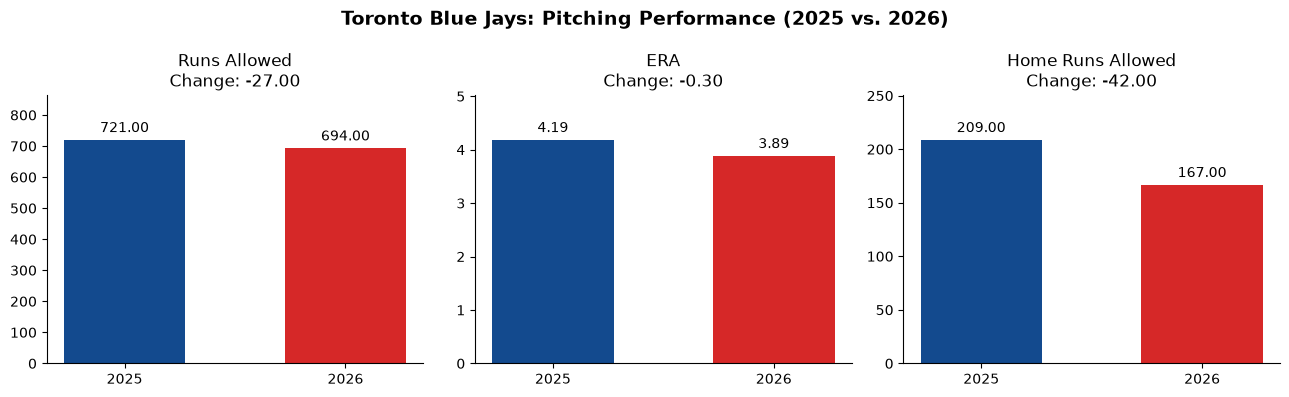

In [3]:

# Key pitching metrics to compare
metrics = ["runs_allowed", "era", "home_runs_allowed"]
titles = ["Runs Allowed", "ERA", "Home Runs Allowed"]

# Create three separate charts, each with its own scale
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

# Set season as the index
pitching_plot = team_pitching.set_index("season")

# Generate one bar chart for each metric
for i, metric in enumerate(metrics):

    values = pitching_plot.loc[[2025, 2026], metric]

    # Plot 2025 and 2026 using different colors
    bars = axes[i].bar(
        ["2025", "2026"],
        values,
        color=["#134A8E", "#D62828"],
        width=0.55
    )

    # Calculate and display the change
    change = values.loc[2026] - values.loc[2025]
    axes[i].set_title(f"{titles[i]}\nChange: {change:+.2f}")

    # Display the exact value above each bar
    axes[i].bar_label(bars, fmt="%.2f", padding=3)

    # Use an independent scale starting at zero
    axes[i].set_ylim(0, values.max() * 1.2)

    # Remove unnecessary chart borders
    axes[i].spines["top"].set_visible(False)
    axes[i].spines["right"].set_visible(False)

# Add an overall title
fig.suptitle("Toronto Blue Jays: Pitching Performance (2025 vs. 2026)",
             fontsize=14, fontweight="bold")

plt.tight_layout()
plt.show()



### 3.3 Starting Rotation vs. Bullpen

Although Toronto's overall pitching performance improved in 2026, this improvement may not have been equally distributed between starting pitchers and relievers.

To investigate the composition of the pitching staff, we first classify pitchers based on their games played (`G`) and games started (`GS`):

- **Starting Only:** All pitching appearances were starts.
- **Relief Only:** No games started.
- **Mixed Role:** Appeared as both a starter and reliever.

This classification helps us understand how the pitching staff was structured across both seasons.

**Limitation:** Individual season totals do not separate statistics accumulated during starts from those accumulated in relief. Therefore, a precise comparison of rotation and bullpen ERA would require appearance-level data.


In [5]:

# Create a list to store pitching role counts for each season
role_counts = []

# Examine the pitching staff in each season
for season, df in [(2025, pitching_2025), (2026, pitching_2026)]:

    # Pitchers who started every game they appeared in
    starters = ((df["GS"] > 0) & (df["GS"] == df["G"])).sum()

    # Pitchers who appeared exclusively in relief
    relievers = (df["GS"] == 0).sum()

    # Pitchers who made both starting and relief appearances
    mixed = ((df["GS"] > 0) & (df["GS"] < df["G"])).sum()

    # Store the results for this season
    role_counts.append({
        "Season": season,
        "Starting Only": starters,
        "Relief Only": relievers,
        "Mixed Role": mixed
    })

# Convert results into a comparison table
role_summary = pd.DataFrame(role_counts).set_index("Season")

display(role_summary)


,Starting Only,Relief Only,Mixed Role
Season,,,
2025,5,23,10
2026,8,25,8



**Key Findings: Pitching Staff Composition**

Toronto utilized 38 pitchers in 2025 compared with 41 in 2026.

- Pitchers appearing exclusively as starters increased from 5 to 8.
- Relief-only pitchers increased from 23 to 25.
- Pitchers serving in both roles decreased from 10 to 8.

These findings indicate changes in pitching staff composition and usage between seasons.

However, role classifications alone cannot establish whether the starting rotation or bullpen improved. We must also consider individual workloads and pitching efficiency.

In [6]:

# Identify pitchers with at least 10 starts in each season
for season, df in [(2025, pitching_2025), (2026, pitching_2026)]:

    # Filter for pitchers with 10 or more games started
    starters = df[df["GS"] >= 10]

    # Select relevant statistics and sort by games started
    starters = starters[["Player", "G", "GS", "IP", "ERA"]].sort_values(
        "GS", ascending=False
    )

    # Display starting pitcher statistics
    print(f"\n{season} Starting Pitchers (10+ Starts)")
    display(starters)



2025 Starting Pitchers (10+ Starts)


,Player,G,GS,IP,ERA
0,Kevin Gausman,32,32,193.0,3.59
1,Chris Bassitt,32,31,170.1,3.96
2,José Berríos,31,30,166.0,4.17
4,Max Scherzer,17,17,85.0,5.19
3,Eric Lauer,28,15,104.2,3.18
5,Bowden Francis,14,14,64.0,6.05



2026 Starting Pitchers (10+ Starts)


,Player,G,GS,IP,ERA
0,Dylan Cease,29,29,169.0,2.40
1,Kevin Gausman,23,23,127.1,4.38
2,Trey Yesavage,20,20,97.2,3.69
3,Max Scherzer,18,18,84.2,5.74
4,Patrick Corbin,19,15,80.0,5.51
5,Shane Bieber,11,11,55.2,4.37
7,Braydon Fisher,75,10,75.2,3.21
12,José Soriano,10,10,54.1,5.30



### 3.4 Primary Starting Pitchers

To identify pitchers who contributed significantly to Toronto's starting rotation, we apply two criteria:

- At least 10 games started (`GS >= 10`).
- At least 50% of total appearances were starts (`GS / G >= 0.50`).

These criteria help distinguish rotation-focused pitchers from relievers who occasionally started games.

We will compare their workloads and pitching efficiency to identify notable changes between seasons.

**Note:** Individual season statistics include both starting and relief appearances where applicable. Therefore, these comparisons describe rotation-focused pitchers, not exclusively their performances as starters.


In [7]:

# Identify rotation-focused pitchers in each season
for season, df in [(2025, pitching_2025), (2026, pitching_2026)]:

    # Keep pitchers with 10+ starts and at least 50% starting appearances
    rotation = df[
        (df["GS"] >= 10) &
        (df["GS"] / df["G"] >= 0.50)
    ].copy()

    # Calculate the percentage of appearances made as a starter
    rotation["Start %"] = (rotation["GS"] / rotation["G"] * 100).round(1)

    # Select relevant statistics and sort by games started
    rotation = rotation[
        ["Player", "G", "GS", "Start %", "IP", "ERA"]
    ].sort_values("GS", ascending=False)

    print(f"\n{season} Primary Starting Pitchers")
    display(rotation)



2025 Primary Starting Pitchers


,Player,G,GS,Start %,IP,ERA
0,Kevin Gausman,32,32,100.0,193.0,3.59
1,Chris Bassitt,32,31,96.9,170.1,3.96
2,José Berríos,31,30,96.8,166.0,4.17
4,Max Scherzer,17,17,100.0,85.0,5.19
3,Eric Lauer,28,15,53.6,104.2,3.18
5,Bowden Francis,14,14,100.0,64.0,6.05



2026 Primary Starting Pitchers


,Player,G,GS,Start %,IP,ERA
0,Dylan Cease,29,29,100.0,169.0,2.40
1,Kevin Gausman,23,23,100.0,127.1,4.38
2,Trey Yesavage,20,20,100.0,97.2,3.69
3,Max Scherzer,18,18,100.0,84.2,5.74
4,Patrick Corbin,19,15,78.9,80.0,5.51
5,Shane Bieber,11,11,100.0,55.2,4.37
12,José Soriano,10,10,100.0,54.1,5.30



### 3.5 Rotation-Focused Pitchers: Workload and Efficiency

Having identified Toronto's primary starting pitchers, we can now evaluate their collective pitching performance.

We will compare:

- **Total Innings Pitched:** Measures the workload handled by rotation-focused pitchers.
- **Earned Runs Allowed:** Measures the total earned runs surrendered by this group.
- **Collective ERA:** Evaluates earned run prevention relative to innings pitched.

Rather than averaging individual ERAs, we calculate collective ERA using total earned runs and total innings pitched.

Because baseball records innings in thirds rather than ordinary decimals, innings pitched must first be converted into outs to ensure accurate calculations.

**Limitation:** These statistics include any relief appearances made by rotation-focused pitchers and therefore do not represent an exact starting rotation split.


In [8]:

# Convert baseball innings notation into total outs
# Example: 170.1 IP = 170 innings + 1 out = 511 outs
def innings_to_outs(ip):
    innings = int(ip)
    extra_outs = round((ip - innings) * 10)
    return innings * 3 + extra_outs

# Store each season's rotation statistics
rotation_results = []

for season, df in [(2025, pitching_2025), (2026, pitching_2026)]:

    # Select rotation-focused pitchers using our established criteria
    rotation = df[
        (df["GS"] >= 10) &
        (df["GS"] / df["G"] >= 0.50)
    ].copy()

    # Convert innings pitched to outs before adding workloads
    total_outs = rotation["IP"].apply(innings_to_outs).sum()

    # Convert total outs into actual innings
    total_ip = total_outs / 3

    # Calculate collective earned runs and ERA
    total_er = rotation["ER"].sum()
    collective_era = (total_er * 9) / total_ip

    # Save the results
    rotation_results.append({
        "Season": season,
        "Pitchers": len(rotation),
        "Total IP": round(total_ip, 1),
        "Earned Runs": total_er,
        "Collective ERA": round(collective_era, 2)
    })

# Create a comparison table
rotation_summary = pd.DataFrame(rotation_results).set_index("Season")

display(rotation_summary)


,Pitchers,Total IP,Earned Runs,Collective ERA
Season,,,,
2025,6,783.0,358,4.11
2026,7,668.7,309,4.16



**Key Findings: Rotation-Focused Pitchers**

Toronto's rotation-focused pitchers experienced a slight decline in collective pitching efficiency between 2025 and 2026.

- **Collective ERA:** Increased from 4.11 to 4.16, indicating a small deterioration in earned-run prevention.
- **Workload:** Decreased from 783 innings to approximately 669 innings.
- **Earned Runs:** Decreased from 358 to 309, although this reduction occurred alongside a substantial decrease in innings pitched.

Despite Toronto's overall team ERA improving from 4.19 to 3.89, the rotation-focused group's collective ERA remained relatively unchanged.

This suggests that the improvement in team pitching may have been driven by pitchers outside our selected rotation group.

**Analytical Limitation:** Rotation-focused pitchers were identified using a minimum of 10 starts and a starting appearance rate of at least 50%. Their season statistics may include relief appearances, so these results should not be interpreted as an exact starting rotation ERA.



### 3.6 Comparing Rotation-Focused and Other Pitchers

To investigate which pitchers contributed to Toronto's improved team ERA, we divide the pitching staff into two mutually exclusive groups:

- **Rotation-Focused Pitchers:** At least 10 starts, with starts accounting for 50% or more of their appearances.
- **Other Pitchers:** All remaining pitchers, including relievers, occasional starters, and pitchers with fewer than 10 starts.

We will compare each group's collective ERA, innings pitched, and earned runs allowed between seasons.

This approach allows us to investigate differences in pitching efficiency while accounting for workload.

**Limitation:** These categories describe groups of pitchers rather than individual appearances. Therefore, the results should not be interpreted as official starting rotation and bullpen statistics.


In [9]:

# Store statistics for pitchers outside our rotation-focused group
other_results = []

for season, df in [(2025, pitching_2025), (2026, pitching_2026)]:

    # Select pitchers who do NOT meet our rotation criteria
    other_pitchers = df[
        ~((df["GS"] >= 10) & (df["GS"] / df["G"] >= 0.50))
    ].copy()

    # Convert baseball innings notation into outs
    total_outs = other_pitchers["IP"].apply(innings_to_outs).sum()
    total_ip = total_outs / 3

    # Calculate total earned runs and collective ERA
    total_er = other_pitchers["ER"].sum()
    collective_era = (total_er * 9) / total_ip

    # Save results
    other_results.append({
        "Season": season,
        "Pitchers": len(other_pitchers),
        "Total IP": round(total_ip, 1),
        "Earned Runs": total_er,
        "Collective ERA": round(collective_era, 2)
    })

# Create a comparison table
other_summary = pd.DataFrame(other_results).set_index("Season")

display(other_summary)


,Pitchers,Total IP,Earned Runs,Collective ERA
Season,,,,
2025,32,655.0,311,4.27
2026,34,767.3,314,3.68



### 3.7 Pitching Efficiency by Group

The following visualization compares the collective ERA of rotation-focused pitchers and other pitchers during the 2025 and 2026 seasons.

Lower ERA values indicate better earned-run prevention.

This comparison helps identify which group experienced the greatest improvement or deterioration in pitching efficiency.


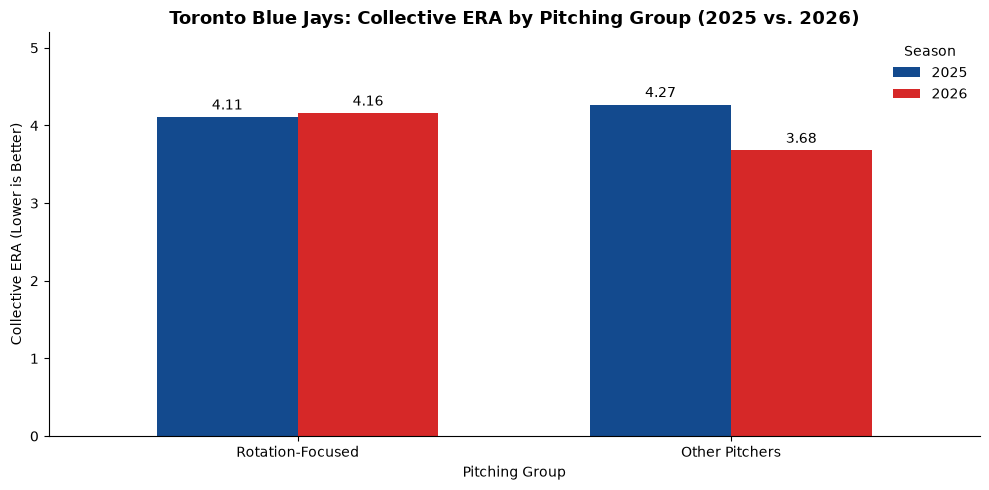

In [14]:

# Combine collective ERA results from both pitching groups
era_comparison = pd.DataFrame({
    "Rotation-Focused": rotation_summary["Collective ERA"],
    "Other Pitchers": other_summary["Collective ERA"]
})

# Create a grouped bar chart
ax = era_comparison.T.plot(
    kind="bar",
    figsize=(10, 5),
    color=["#134A8E", "#D62828"],
    width=0.65
)

# Add descriptive chart labels
ax.set_title(
    "Toronto Blue Jays: Collective ERA by Pitching Group (2025 vs. 2026)",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel("Pitching Group")
ax.set_ylabel("Collective ERA (Lower is Better)")
ax.set_xticklabels(["Rotation-Focused", "Other Pitchers"], rotation=0)

# Display exact ERA values above the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3)

# Keep the y-axis starting at zero
ax.set_ylim(0, 5.2)

# Improve presentation
ax.legend(title="Season", frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()



### 3.8 Pitching Workload Distribution

Pitching efficiency alone does not fully explain a group's contribution. We must also consider how many innings each group pitched.

The following visualization compares the distribution of innings pitched by rotation-focused and other pitchers in 2025 and 2026.

This allows us to examine whether changes in pitching workload accompanied the differences in collective ERA identified previously.


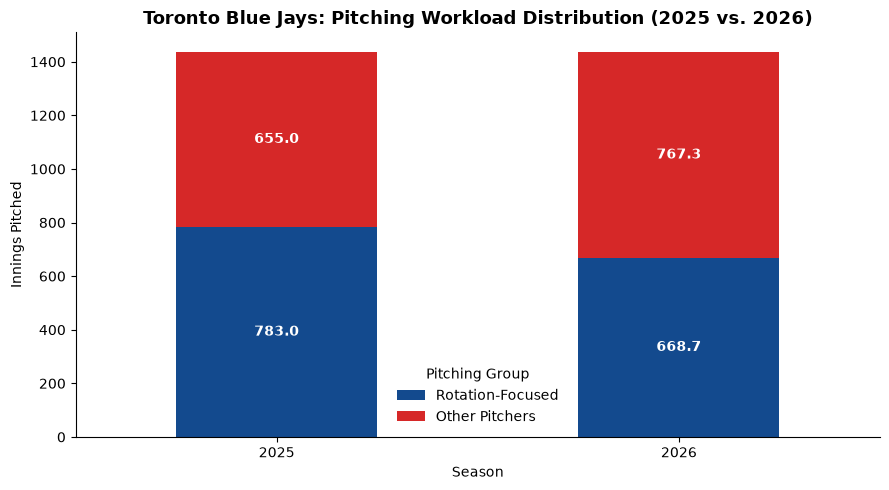

In [12]:

# Combine innings pitched from both pitching groups
workload_comparison = pd.DataFrame({
    "Rotation-Focused": rotation_summary["Total IP"],
    "Other Pitchers": other_summary["Total IP"]
})

# Create a stacked bar chart
ax = workload_comparison.plot(
    kind="bar",
    stacked=True,
    figsize=(9, 5),
    color=["#134A8E", "#D62828"],
    width=0.5
)

# Add chart title and labels
ax.set_title(
    "Toronto Blue Jays: Pitching Workload Distribution (2025 vs. 2026)",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel("Season")
ax.set_ylabel("Innings Pitched")
ax.set_xticklabels(["2025", "2026"], rotation=0)

# Display workload values inside each bar segment
for container in ax.containers:
    ax.bar_label(
        container,
        label_type="center",
        fmt="%.1f",
        color="white",
        fontweight="bold"
    )

# Clean up chart appearance
ax.legend(title="Pitching Group", frameon=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()



### 3.9 Key Findings: Pitching Efficiency and Workload

Our analysis reveals that Toronto's improved team pitching performance in 2026 was not equally distributed across the pitching staff.

**1. Rotation-Focused Pitchers**

- Collective ERA increased slightly from **4.11 to 4.16**, indicating relatively stable but marginally worse earned-run prevention.
- Total workload decreased from **783.0 to approximately 668.7 decimal innings**, a reduction of roughly 114 innings.
- Despite featuring seven rotation-focused pitchers in 2026 compared with six in 2025, this group contributed fewer total innings.

**2. Other Pitchers**

- Collective ERA improved substantially from **4.27 to 3.68**, a decrease of 0.59.
- Total workload increased from **655.0 to approximately 767.3 decimal innings**, an increase of roughly 112 innings.
- Earned runs allowed remained nearly unchanged (311 vs. 314), despite the greater workload.

**3. Overall Interpretation**

These results suggest that Toronto's improvement in team pitching was concentrated among pitchers outside our rotation-focused group.

While the rotation-focused group's collective ERA remained relatively stable, the other pitchers provided more innings with substantially improved earned-run prevention.

This contrast helps explain how Toronto's overall team ERA improved from 4.19 to 3.89 despite modest deterioration among its primary starting pitchers.

**Analytical Limitations**

Our classification is based on season-level pitcher statistics rather than individual game appearances. Therefore, the results represent groups of pitchers, not exact starting rotation and bullpen performance.

Additionally, these findings describe statistical associations rather than establishing the causes of Toronto's pitching improvements.



---

## 4. Individual Pitcher Performance Analysis

### 4.1 Identifying Returning Pitchers

While team-level statistics provide an overview of Toronto's pitching performance, individual-player analysis helps identify which pitchers contributed to changes between seasons.

We begin by identifying pitchers who appeared for the Blue Jays in both 2025 and 2026.

Using an inner join, we will match pitchers across seasons and compare their individual statistics.

Our analysis will focus on:

- **Pitching Efficiency:** ERA, WHIP, and other relevant performance indicators.
- **Workload:** Changes in innings pitched and appearances.
- **Consistency:** Identifying returning pitchers who improved or declined.
- **Individual Contributions:** Understanding how these changes relate to the team's overall pitching performance.

Because pitchers can have substantially different workloads, we will establish a minimum innings-pitched threshold before making detailed performance comparisons.


In [15]:

# Match pitchers who appeared in both the 2025 and 2026 seasons
returning_pitchers = pd.merge(
    pitching_2025,
    pitching_2026,
    on="Player",
    how="inner",
    suffixes=("_2025", "_2026")
)

# Count the number of returning pitchers
print("Number of Returning Pitchers:", len(returning_pitchers))

# Display returning pitchers and their innings pitched in each season
display(
    returning_pitchers[
        ["Player", "IP_2025", "IP_2026"]
    ].sort_values("Player").reset_index(drop=True)
)


Number of Returning Pitchers: 14


,Player,IP_2025,IP_2026
0,Braydon Fisher,50.0,75.2
1,Brendon Little,68.1,28.1
2,Eric Lauer,104.2,36.1
3,Jeff Hoffman,68.0,48.0
4,Kevin Gausman,193.0,127.1
5,Louis Varland,23.2,78.0
6,Lázaro Estrada,7.1,13.0
7,Mason Fluharty,52.2,62.2
8,Max Scherzer,85.0,84.2
9,Shane Bieber,40.1,55.2



### 4.2 Establishing a Minimum Workload Threshold

To compare returning pitchers fairly, we will focus on players who recorded at least **20 innings pitched in both seasons**.

This threshold allows us to retain more returning pitchers while excluding players with extremely limited appearances.

Although 20 innings does not guarantee statistical reliability, it provides a practical starting point for comparing changes in ERA, WHIP, and pitching workload.

Pitchers who do not meet this threshold will remain part of our broader analysis of pitching personnel changes.


In [17]:

# Convert innings pitched into outs for accurate comparisons
returning_pitchers["Outs_2025"] = returning_pitchers["IP_2025"].apply(innings_to_outs)
returning_pitchers["Outs_2026"] = returning_pitchers["IP_2026"].apply(innings_to_outs)

# Keep pitchers with at least 20 innings (60 outs) in BOTH seasons
qualified_pitchers = returning_pitchers[
    (returning_pitchers["Outs_2025"] >= 60) &
    (returning_pitchers["Outs_2026"] >= 60)
].copy()

# Display qualified pitchers and their workloads
print("Qualified Returning Pitchers:", len(qualified_pitchers))

display(
    qualified_pitchers[
        ["Player", "IP_2025", "IP_2026"]
    ].sort_values("Player").reset_index(drop=True)
)


Qualified Returning Pitchers: 10


,Player,IP_2025,IP_2026
0,Braydon Fisher,50.0,75.2
1,Brendon Little,68.1,28.1
2,Eric Lauer,104.2,36.1
3,Jeff Hoffman,68.0,48.0
4,Kevin Gausman,193.0,127.1
5,Louis Varland,23.2,78.0
6,Mason Fluharty,52.2,62.2
7,Max Scherzer,85.0,84.2
8,Shane Bieber,40.1,55.2
9,Tommy Nance,31.2,33.0



### 4.3 Returning Pitchers: ERA and WHIP Comparison

We now examine changes in pitching efficiency among the 10 returning pitchers who recorded at least 20 innings in both seasons.

Two metrics will be used:

- **ERA (Earned Run Average):** Measures earned runs allowed per nine innings.
- **WHIP (Walks Plus Hits per Inning Pitched):** Measures the average number of baserunners allowed per inning through walks and hits.

For both statistics, lower values indicate better performance.

By calculating the difference between 2026 and 2025, we can identify pitchers who improved or declined in these measures.

These comparisons will be interpreted alongside pitching workloads, as smaller samples can produce greater statistical variability.


In [18]:

# Calculate changes in ERA and WHIP (2026 minus 2025)
qualified_pitchers["ERA Change"] = (
    qualified_pitchers["ERA_2026"] - qualified_pitchers["ERA_2025"]
)

qualified_pitchers["WHIP Change"] = (
    qualified_pitchers["WHIP_2026"] - qualified_pitchers["WHIP_2025"]
)

# Create a comparison table with both seasons' statistics
pitcher_comparison = qualified_pitchers[
    [
        "Player",
        "ERA_2025", "ERA_2026", "ERA Change",
        "WHIP_2025", "WHIP_2026", "WHIP Change"
    ]
].copy()

# Sort by ERA change: most improved pitchers appear first
pitcher_comparison = pitcher_comparison.sort_values("ERA Change")

# Display the results
display(pitcher_comparison.round(2).reset_index(drop=True))


,Player,ERA_2025,ERA_2026,ERA Change,WHIP_2025,WHIP_2026,WHIP Change
0,Louis Varland,4.94,1.27,-3.67,1.39,1.00,-0.39
1,Mason Fluharty,4.44,3.30,-1.14,1.14,1.25,0.11
2,Jeff Hoffman,4.37,3.94,-0.43,1.19,1.38,0.18
3,Braydon Fisher,2.70,3.21,0.51,1.02,1.27,0.25
4,Max Scherzer,5.19,5.74,0.55,1.29,1.34,0.04
5,Kevin Gausman,3.59,4.38,0.79,1.06,1.29,0.23
6,Shane Bieber,3.57,4.37,0.80,1.02,1.42,0.40
7,Tommy Nance,1.99,3.82,1.83,1.01,1.27,0.26
8,Brendon Little,3.03,6.35,3.32,1.36,1.91,0.54
9,Eric Lauer,3.18,6.69,3.51,1.11,1.49,0.38



### 4.4 Visualizing Changes in Returning Pitchers' ERA

The following chart illustrates changes in ERA among the 10 qualified returning pitchers.

- **Negative changes (green):** Improved ERA in 2026.
- **Positive changes (red):** Worsened ERA in 2026.

The visualization highlights individual performance differences that may be obscured by team-level statistics.

ERA changes should be interpreted alongside innings pitched, as individual workloads differed between seasons.


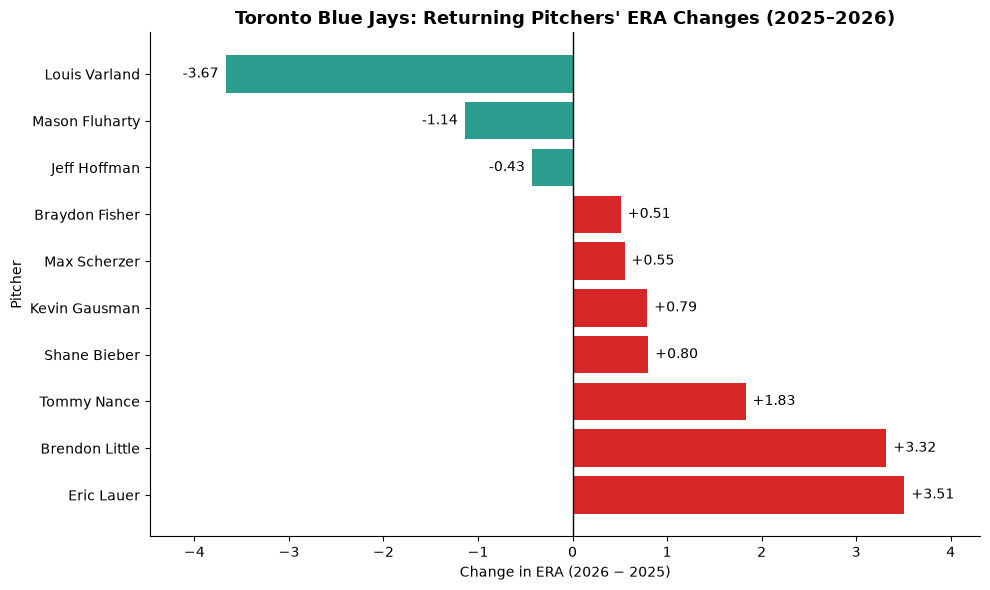

In [19]:

# Sort pitchers by ERA change, from greatest improvement to greatest decline
era_plot = pitcher_comparison.sort_values("ERA Change")

# Assign green to improvements and red to declines
colors = [
    "#2A9D8F" if change < 0 else "#D62828"
    for change in era_plot["ERA Change"]
]

# Create a horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    era_plot["Player"],
    era_plot["ERA Change"],
    color=colors
)

# Add a vertical reference line representing no change
ax.axvline(0, color="black", linewidth=1)

# Add numerical values at the end of each bar
for bar, change in zip(bars, era_plot["ERA Change"]):
    ax.annotate(
        f"{change:+.2f}",
        xy=(change, bar.get_y() + bar.get_height() / 2),
        xytext=(5 if change >= 0 else -5, 0),
        textcoords="offset points",
        ha="left" if change >= 0 else "right",
        va="center"
    )

# Add chart labels
ax.set_title(
    "Toronto Blue Jays: Returning Pitchers' ERA Changes (2025–2026)",
    fontsize=13,
    fontweight="bold"
)
ax.set_xlabel("Change in ERA (2026 − 2025)")
ax.set_ylabel("Pitcher")

# Display greatest improvements at the top
ax.invert_yaxis()

# Add space for value labels and clean up chart borders
ax.set_xlim(
    era_plot["ERA Change"].min() - 0.8,
    era_plot["ERA Change"].max() + 0.8
)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()



### 4.5 Key Findings: Returning Pitchers

Among the 10 returning pitchers who recorded at least 20 innings in both seasons, individual pitching efficiency generally deteriorated in 2026.

- **7 of 10 pitchers** recorded higher ERAs, while only three improved.
- **Louis Varland** demonstrated the largest improvement, reducing his ERA from 4.94 to 1.27 while increasing his workload.
- **Eric Lauer and Brendon Little** experienced the largest ERA increases, rising by 3.51 and 3.32, respectively.
- **9 of 10 pitchers** recorded higher WHIPs, suggesting that most returning pitchers allowed more baserunners per inning.
- **Mason Fluharty and Jeff Hoffman** improved their ERAs despite recording higher WHIPs, illustrating the importance of evaluating multiple performance metrics.

**Interpretation:**

Although Toronto's overall team ERA improved in 2026, most qualified returning pitchers experienced declining individual efficiency.

This suggests that improvements elsewhere in the pitching staff may have offset deterioration among returning pitchers.

However, individual ERA changes do not account for differences in pitching workload. A collective analysis is necessary before determining whether returning pitchers became less effective as a group.



### 4.6 Collective Performance of Qualified Returning Pitchers

To determine whether returning pitchers became less effective collectively, we calculate their combined pitching statistics for both seasons.

Our comparison includes:

- Total innings pitched
- Total earned runs allowed
- Collective ERA

By accounting for pitching workload, this analysis provides a more representative measure of the returning group's overall earned-run prevention than a simple average of individual ERAs.

The comparison includes only pitchers who recorded at least 20 innings in both seasons.


In [20]:

# Store collective pitching statistics for both seasons
returning_results = []

for season in [2025, 2026]:

    # Calculate total innings using outs for baseball notation
    total_outs = qualified_pitchers[f"Outs_{season}"].sum()
    total_ip = total_outs / 3

    # Sum earned runs allowed by the qualified returning pitchers
    total_er = qualified_pitchers[f"ER_{season}"].sum()

    # Calculate collective ERA using total earned runs and innings
    collective_era = (total_er * 9) / total_ip

    # Store the season's results
    returning_results.append({
        "Season": season,
        "Pitchers": len(qualified_pitchers),
        "Total IP": round(total_ip, 1),
        "Earned Runs": total_er,
        "Collective ERA": round(collective_era, 2)
    })

# Create and display the comparison table
returning_summary = pd.DataFrame(returning_results).set_index("Season")

display(returning_summary)


,Pitchers,Total IP,Earned Runs,Collective ERA
Season,,,,
2025,10,717.3,296,3.71
2026,10,629.7,286,4.09



**Key Findings: Collective Returning Pitcher Performance**

The 10 qualified returning pitchers experienced a decline in collective pitching efficiency between 2025 and 2026.

- **Collective ERA:** Increased from 3.71 to 4.09, representing a deterioration of 0.38 earned runs per nine innings.
- **Total Workload:** Decreased from approximately 717 to 630 decimal innings, a reduction of nearly 88 innings.
- **Earned Runs Allowed:** Decreased slightly from 296 to 286, despite the substantial reduction in workload.

**Interpretation:**

Although Toronto's overall team ERA improved from 4.19 to 3.89, the qualified returning pitchers collectively became less effective at preventing earned runs.

This finding supports our individual analysis, which showed that seven of the ten qualified returning pitchers recorded higher ERAs in 2026.

Together, these results suggest that improvements among other members of the pitching staff may have offset the deterioration of returning pitchers.

However, the collective comparison only includes returning pitchers who met our 20-inning threshold in both seasons. It does not represent every returning pitcher.

To investigate the remaining changes in team pitching performance, we will next examine pitchers who appeared exclusively in either the 2025 or 2026 season.



---

## 5. Pitching Personnel Changes

### 5.1 Identifying 2025-Only and 2026-Only Pitchers

Our previous analysis revealed that qualified returning pitchers experienced a decline in collective ERA, despite Toronto's overall team ERA improving in 2026.

To investigate this difference, we will examine changes in pitching personnel between seasons.

We divide pitchers into three categories:

- **Returning Pitchers:** Appeared in both 2025 and 2026.
- **2025-Only Pitchers:** Appeared in 2025 but not 2026.
- **2026-Only Pitchers:** Appeared in 2026 but not 2025.

By comparing the workloads and pitching efficiency of the 2025-only and 2026-only groups, we can evaluate how changes in pitching personnel contributed to Toronto's overall performance.

**Note:** These categories describe appearances in the available datasets. They do not establish whether a player was traded, released, injured, or acquired.


In [21]:

# Identify all pitchers who appeared in each season
players_2025 = set(pitching_2025["Player"])
players_2026 = set(pitching_2026["Player"])

# Find pitchers who appeared in only one of the two seasons
only_2025 = players_2025 - players_2026
only_2026 = players_2026 - players_2025

# Create separate DataFrames for each group
pitchers_only_2025 = pitching_2025[
    pitching_2025["Player"].isin(only_2025)
].copy()

pitchers_only_2026 = pitching_2026[
    pitching_2026["Player"].isin(only_2026)
].copy()

# Display the number of pitchers in each group
print("2025-Only Pitchers:", len(pitchers_only_2025))
print("2026-Only Pitchers:", len(pitchers_only_2026))

# Display each group's pitchers and key statistics
columns = ["Player", "IP", "ERA", "WHIP"]

print("\n2025-Only Pitchers:")
display(pitchers_only_2025[columns].sort_values("IP", ascending=False))

print("\n2026-Only Pitchers:")
display(pitchers_only_2026[columns].sort_values("IP", ascending=False))


2025-Only Pitchers: 24
2026-Only Pitchers: 27

2025-Only Pitchers:


,Player,IP,ERA,WHIP
1,Chris Bassitt,170.1,3.96,1.327
2,José Berríos,166.0,4.17,1.301
5,Bowden Francis,64.0,6.05,1.531
11,Chad Green,43.2,5.56,1.466
14,Paxton Schultz,24.2,4.38,1.419
15,Easton Lucas,24.1,6.66,1.521
17,Seranthony Domínguez,21.0,3.00,1.143
18,Yimi García,21.0,3.86,1.190
19,Nick Sandlin,16.1,2.20,1.163
21,Justin Bruihl,13.2,5.27,1.902



2026-Only Pitchers:


,Player,IP,ERA,WHIP
0,Dylan Cease,169.0,2.40,1.101
11,Spencer Miles,95.2,2.63,1.098
4,Patrick Corbin,80.0,5.51,1.538
8,Tyler Rogers,71.0,1.77,1.169
12,José Soriano,54.1,5.30,1.362
16,Joe Mantiply,27.0,3.00,1.185
17,Spencer Arrighetti,22.2,6.35,1.544
18,Adam Macko,22.0,4.91,1.545
19,Simeon Woods Richardson,18.1,3.93,1.418
20,Chad Dallas,14.1,5.02,1.465



### 5.2 Collective Performance of Season-Exclusive Pitchers

To evaluate the impact of pitching personnel changes, we compare the collective performance of pitchers who appeared exclusively in 2025 or 2026.

Our analysis examines total innings pitched, earned runs allowed, and collective ERA.

Unlike individual ERA comparisons, collective ERA accounts for differences in workload, ensuring that pitchers who contributed more innings have an appropriate influence on the group's results.

This comparison will help determine whether the 2026-only pitching group provided more effective run prevention than the 2025-only group.


In [22]:

# Store the collective statistics for each season-exclusive group
personnel_results = []

for season, df in [(2025, pitchers_only_2025), (2026, pitchers_only_2026)]:

    # Convert baseball innings notation into outs before summing
    total_outs = df["IP"].apply(innings_to_outs).sum()
    total_ip = total_outs / 3

    # Calculate total earned runs and collective ERA
    total_er = df["ER"].sum()
    collective_era = (total_er * 9) / total_ip

    # Store each group's results
    personnel_results.append({
        "Season": season,
        "Pitchers": len(df),
        "Total IP": round(total_ip, 1),
        "Earned Runs": total_er,
        "Collective ERA": round(collective_era, 2)
    })

# Create a comparison table
personnel_summary = pd.DataFrame(personnel_results).set_index("Season")

display(personnel_summary)


,Pitchers,Total IP,Earned Runs,Collective ERA
Season,,,,
2025,24,623.0,324,4.68
2026,27,683.0,276,3.64



### 5.3 Visualizing Season-Exclusive Pitcher Contributions

The following visualization compares the collective ERA and total innings pitched of the 2025-only and 2026-only pitching groups.

By examining both efficiency and workload, we can evaluate whether the changing pitching staff contributed more effective innings in 2026.

Lower ERA indicates better earned-run prevention, while total innings pitched measures each group's overall workload.


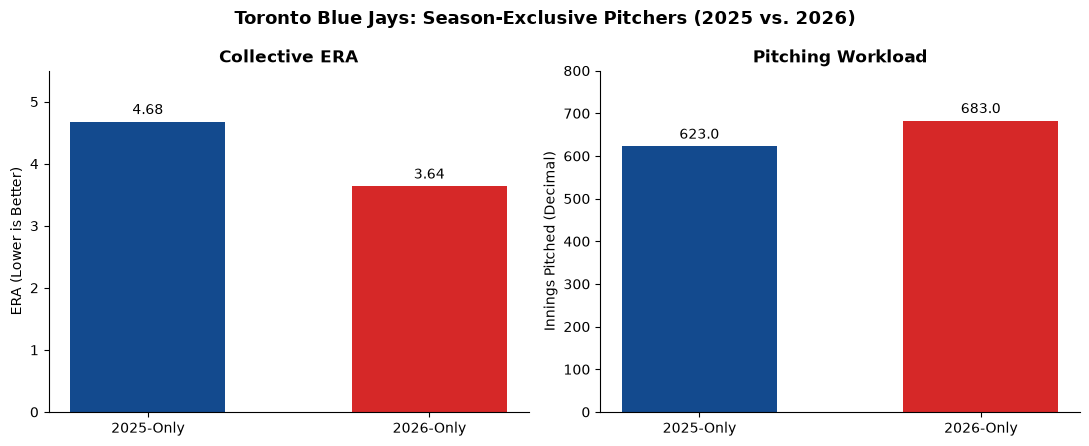

In [23]:

# Create two charts to compare efficiency and workload
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# Define consistent colors for each season
colors = ["#134A8E", "#D62828"]
seasons = ["2025-Only", "2026-Only"]

# Chart 1: Collective ERA
bars1 = axes[0].bar(
    seasons,
    personnel_summary["Collective ERA"],
    color=colors,
    width=0.55
)

axes[0].set_title("Collective ERA", fontweight="bold")
axes[0].set_ylabel("ERA (Lower is Better)")
axes[0].set_ylim(0, 5.5)
axes[0].bar_label(bars1, fmt="%.2f", padding=3)

# Chart 2: Total innings pitched
bars2 = axes[1].bar(
    seasons,
    personnel_summary["Total IP"],
    color=colors,
    width=0.55
)

axes[1].set_title("Pitching Workload", fontweight="bold")
axes[1].set_ylabel("Innings Pitched (Decimal)")
axes[1].set_ylim(0, 800)
axes[1].bar_label(bars2, fmt="%.1f", padding=3)

# Remove unnecessary borders from both charts
for ax in axes:
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

# Add an overall title
fig.suptitle(
    "Toronto Blue Jays: Season-Exclusive Pitchers (2025 vs. 2026)",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### 5.4 Key Findings: Pitching Personnel Changes

The analysis reveals substantial changes in Toronto's pitching personnel between the 2025 and 2026 seasons.

Of the 38 pitchers who appeared in 2025, only 14 returned in 2026. Meanwhile, 27 pitchers appeared in 2026 who were not present in the previous season's pitching dataset.

**Key Findings:**

- **Improved Efficiency:** The 2026-only pitching group recorded a collective ERA of 3.64, compared with 4.68 for the 2025-only group.
- **Greater Workload:** The 2026-only pitchers contributed 683 innings, compared with 623 innings from the 2025-only group.
- **Fewer Earned Runs:** Despite pitching 60 additional innings, the 2026-only group allowed 48 fewer earned runs.
- **Significant Contributors:** Dylan Cease, Spencer Miles, and Tyler Rogers provided substantial innings with strong individual ERAs in 2026.

**Interpretation:**

Pitchers appearing exclusively in 2026 collectively delivered more effective run prevention than those appearing exclusively in 2025.

This contrasts with the deterioration observed among qualified returning pitchers, whose collective ERA increased from 3.71 to 4.09.

These findings suggest that changes in pitching personnel helped offset declines among returning players and contributed to Toronto's improved overall pitching performance.

**Limitations:**

Season-exclusive classifications indicate whether pitchers appeared in the available datasets, not the reasons for roster changes.

Furthermore, these comparisons describe differences between groups rather than establishing the causal effect of individual roster decisions.



---

## 6. Final Pitching Analysis Conclusion

### 6.1 Summary of Key Findings

The Toronto Blue Jays experienced a significant decline in overall team performance between 2025 and 2026. However, our pitching analysis reveals that **overall run prevention improved rather than deteriorated**.

The following findings summarize our investigation.

**1. Overall Team Pitching Improved**

- Team ERA decreased from **4.19 to 3.89**.
- Runs allowed declined from **721 to 694**, an improvement of 27 runs.
- Home runs allowed decreased from **209 to 167**.
- However, walks increased by 77, and WHIP rose slightly from 1.27 to 1.29.

These findings indicate improved earned-run and home-run prevention, although not every pitching metric improved.

**2. Pitching Improvements Were Unevenly Distributed**

- Rotation-focused pitchers experienced a slight collective ERA increase from **4.11 to 4.16**.
- Other pitchers improved their collective ERA from **4.27 to 3.68**.
- The rotation-focused group's workload decreased by approximately 114 innings, while the workload of other pitchers increased.

This suggests that improvements outside the rotation-focused group contributed substantially to Toronto's better overall pitching statistics.

**3. Most Qualified Returning Pitchers Declined**

Among the 10 returning pitchers who recorded at least 20 innings in both seasons:

- Seven recorded higher ERAs.
- Nine recorded higher WHIPs.
- Their collective ERA increased from **3.71 to 4.09**.
- Louis Varland demonstrated the largest individual ERA improvement, while Eric Lauer and Brendon Little experienced the largest increases.

These findings reveal deterioration among many returning pitchers despite improved team-level performance.

**4. Season-Exclusive Pitchers Helped Offset Declines**

Changes in pitching personnel were associated with substantially improved production from the season-exclusive group.

- The 2025-only group recorded a collective ERA of **4.68** across 623 innings.
- The 2026-only group recorded a collective ERA of **3.64** across 683 innings.
- The 2026-only pitchers contributed 60 additional innings while allowing 48 fewer earned runs.

Notable 2026-only contributors included Dylan Cease, Spencer Miles, and Tyler Rogers.

These results suggest that the stronger performance of pitchers appearing exclusively in 2026 helped offset deterioration among returning pitchers.

### 6.2 Answering the Research Question

**To what extent did changes in pitching performance contribute to Toronto's decline between the 2025 and 2026 seasons?**

The evidence indicates that deterioration in overall pitching performance was **not the primary explanation** for Toronto's decline.

Despite individual struggles among returning pitchers and increased walks, the team improved its overall ERA and allowed fewer runs in 2026.

When compared with our previous offensive analysis, the difference is substantial:

| Statistic | 2025 | 2026 | Change |
|---|---:|---:|---:|
| Runs Scored | 798 | 648 | -150 |
| Runs Allowed | 721 | 694 | -27 |
| Run Differential | +77 | -46 | -123 |

Toronto's run differential deteriorated by 123 runs. The 150-run decline in offensive production was partially offset by the 27-run improvement in runs allowed.

Therefore, **declining offensive production appears to be the primary statistical contributor to Toronto's worsening run differential**, rather than declining overall pitching performance.

### 6.3 Limitations and Next Steps

Several limitations should be considered:

- Pitching groups were classified using season-level statistics rather than individual game appearances.
- The minimum 20-inning threshold excludes some returning pitchers from detailed efficiency comparisons.
- Changes in pitching statistics do not independently establish the effects of injuries, roster decisions, or other external factors.
- Runs allowed reflect both pitching and defensive performance.

**Next Step: Fielding Analysis**

Although Toronto allowed fewer runs in 2026, pitching statistics alone cannot explain every aspect of run prevention.

The next notebook, `04_Fielding_Analysis.ipynb`, will investigate changes in defensive performance, including errors, fielding percentage, double plays turned, and other available defensive metrics.

Combining offensive, pitching, and fielding findings will help develop a more comprehensive explanation of the Blue Jays' decline.

